# 11 · What is the 2031 call worth? The cost of risk transfer

**Purpose.** Notebook 10 showed that when rates stay high, the notes last much longer if Freddie Mac does not call them in February 2031 (M-2B: 4.4 years with the call, up to 7.4-9.2 years without). This notebook turns that extra life into **money**, from two sides:

- **Investor:** how much more is a note worth if Freddie Mac calls than if it does not, at the same spread? That is the value of the call to the investor.
- **Freddie Mac:** how much does it pay to keep the notes outstanding, and how much credit protection does it get in return? The difference is the **cost of risk transfer**. The extra cost without the call is what Freddie Mac pays by *not* calling.

**Definitions** (all present values on the October 2026 valuation date):
- **call value** = P(with call) − P(no call), both at the DM that matches the Bloomberg ask under the call assumption;
- **spread cost** = PV at SOFR of the coupon spread paid: balance × spread × days/360. SOFR itself is not a cost of risk transfer, because Freddie Mac would pay it on any funding;
- **protection** = PV at SOFR of the write-downs the note absorbs, which is the credit risk actually transferred;
- **net cost** = spread cost − protection.

**Same setup as notebook 10:** 4 rate paths and 3 lock-in strengths (0, 0.025 estimated, 0.20 FHFA), with the pool projected to the 2046 maturity.

**Code.** `src/call_value.py` (new), building on `src/duration.py`.

## 1 · Setup

**What this cell does.** Loads the pool, the team paths and the pricing rates, and extends them to February 2046 as in notebook 10.

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.float_format", "{:,.2f}".format)

from src import collateral_projection as cp, lockin as lk, duration as du, call_value as cv

TABLES, FIGURES = ROOT / "outputs" / "tables", ROOT / "outputs" / "figures"
pool = cp.load_pool()
team = cp.get_scenarios(None)
all_rates = pd.read_csv(lk.PRICING_RATES)
rates = du.extend_rates(all_rates[all_rates.scenario == "base"])
const = lk.constant_rate_paths(team["base"]["hpi"], {"rates -1pp (6.28%)": 6.28, "flat (7.28%)": 7.28, "rates +1pp (8.28%)": 8.28})
paths = {"team base": du.extend_path(team["base"]), **{k: du.extend_path(v) for k, v in const.items()}}
ORDER, CASES = list(paths), list(du.DURATION_CASES)
print(f"Pool ${pool['Current Balance'].sum()/1e9:.2f}bn; rate paths: {ORDER}; lock-in cases: {CASES}")

Pool $19.25bn; rate paths: ['team base', 'rates -1pp (6.28%)', 'flat (7.28%)', 'rates +1pp (8.28%)']; lock-in cases: ['no lock-in', 'lock-in (estimated)', 'lock-in (FHFA)']


**Result.** Same pool ($19.25bn), the same four rate paths and the same three lock-in cases as notebook 10, all extended to February 2046.

## 2 · Run every case

**What this cell does.** For each path and lock-in strength it projects the pool once and runs the waterfall twice, with and without the call. It then computes the investor and Freddie Mac measures and saves them to `outputs/tables/call_value_grid.csv`. The table shows the current balance and coupon spread of each offered note.

In [2]:
grid = cv.run_grid(pool, paths, {k: rates for k in paths})
grid.to_csv(TABLES / "call_value_grid.csv", index=False)
display(grid.groupby("tranche", sort=False)[["face", "coupon_spread_bps"]].first()
        .assign(face_mm=lambda d: d.face / 1e6).drop(columns="face")
        .rename_axis("offered note (current balance)"))

,coupon_spread_bps,face_mm
offered note (current balance),,
A-1,85,203.48
M-1,100,157.81
M-2A,130,37.85
M-2B,130,37.85


**Result.** The four offered notes have **$437 million** outstanding today:

| note | balance | coupon spread |
|---|---|---|
| A-1 | $203.5mm | 85 bp |
| M-1 | $157.8mm | 100 bp |
| M-2A | $37.9mm | 130 bp |
| M-2B | $37.9mm | 130 bp |

Freddie Mac keeps the matching "H" pieces and the B-classes. Only the offered notes are a cash cost of risk transfer, so they are what we measure here.

## 3 · Investor side: value of the call

**What this cell does.** It shows, for each note, the WAL with and without the call and the call value per 100 of face. It then shows the DM an investor buying at the Bloomberg ask would earn under each assumption, for the two high-rate paths.

**How to read it.** A positive call value means the note is worth more if Freddie Mac calls. That is the case for notes bought **below par** (M-2A at 99.72, M-2B at 99.148): the call returns par early, and the investor stops earning a coupon spread below the market's required DM.

**Q&A**

**Q: Why is the call value zero on the team base path?**
A: Because the notes are fully repaid before 2031, so the call never matters.

**Q: Isn't 0.5 points small?**
A: For a note priced at 99.15 it is more than half of the whole discount to par (0.85 points). The no-call risk explains much of why M-2B trades below par.

In [3]:
def pivot(value, scale=1.0):
    t = grid.pivot_table(index=["path", "tranche"], columns="lockin_case", values=value) * scale
    return t.loc[ORDER, CASES]

inv = pd.concat({"WAL call": pivot("wal_call"), "WAL no call": pivot("wal_no_call"),
                 "call value (per 100)": pivot("call_value_per_100")}, axis=1)
inv.to_csv(TABLES / "call_value_investor.csv")
display(inv.rename_axis(["rate path", "note"]))

dm = pd.concat({"DM with call": pivot("dm_call_bps"), "DM without call": pivot("dm_no_call_bps")}, axis=1)
dm.to_csv(TABLES / "call_value_dm.csv")
display(dm.loc[["flat (7.28%)", "rates +1pp (8.28%)"]].rename_axis(["rate path", "DM at ask (bp)"]))

WAL call                                     \
lockin_case             no lock-in lock-in (estimated) lock-in (FHFA)   
rate path          note                                                 
team base          A-1        1.40                1.40           1.40   
                   M-1        1.20                1.20           1.22   
                   M-2A       2.43                2.43           2.45   
                   M-2B       2.82                2.82           2.84   
rates -1pp (6.28%) A-1        1.40                1.40           1.40   
                   M-1        0.61                0.61           0.61   
                   M-2A       1.57                1.57           1.58   
                   M-2B       2.07                2.08           2.08   
flat (7.28%)       A-1        1.40                1.40           1.40   
                   M-1        1.88                1.91           2.04   
                   M-2A       4.31                4.33           4.40   
                   M-2B       4.40                4.40           4.40   
rates +1pp (8.28%) A-1        1.40                1.40           1.40   
                   M-1        2.59                2.66           3.07   
                   M-2A       4.40                4.40           4.40   
                   M-2B       4.40                4.40           4.40   

                        WAL no call                                     \
lockin_case              no lock-in lock-in (estimated) lock-in (FHFA)   
rate path          note                                                  
team base          A-1         1.40                1.40           1.40   
                   M-1         1.20                1.20           1.22   
                   M-2A        2.43                2.43           2.45   
                   M-2B        2.82                2.82           2.84   
rates -1pp (6.28%) A-1         1.40                1.40           1.40   
                   M-1         0.61                0.61           0.61   
                   M-2A        1.57                1.57           1.58   
                   M-2B        2.07                2.08           2.08   
flat (7.28%)       A-1         1.40                1.40           1.40   
                   M-1         1.88                1.91           2.04   
                   M-2A        4.49                4.54           4.86   
                   M-2B        5.60                5.66           6.05   
rates +1pp (8.28%) A-1         1.40                1.40           1.40   
                   M-1         2.69                2.79           3.55   
                   M-2A        6.07                6.26           7.66   
                   M-2B        7.40                7.64           9.22   

                        call value (per 100)                      \
lockin_case                       no lock-in lock-in (estimated)   
rate path          note                                            
team base          A-1                  0.00                0.00   
                   M-1                  0.00                0.00   
                   M-2A                 0.00                0.00   
                   M-2B                 0.00                0.00   
rates -1pp (6.28%) A-1                  0.00                0.00   
                   M-1                  0.00                0.00   
                   M-2A                 0.00                0.00   
                   M-2B                 0.00                0.00   
flat (7.28%)       A-1                  0.00                0.00   
                   M-1                  0.00                0.00   
                   M-2A                 0.01                0.01   
                   M-2B                 0.20                0.21   
rates +1pp (8.28%) A-1                  0.00                0.00   
                   M-1                 -0.00               -0.00   
                   M-2A                 0.09                0.10   
       

DM with call                      \
lockin_case                         no lock-in lock-in (estimated)   
rate path          DM at ask (bp)                                    
flat (7.28%)       A-1                   86.63               86.63   
                   M-1                   98.49               98.51   
                   M-2A                 137.17              137.13   
                   M-2B                 151.46              151.46   
rates +1pp (8.28%) A-1                   86.63               86.63   
                   M-1                   98.88               98.91   
                   M-2A                 137.03              137.03   
                   M-2B                 151.46              151.46   

                                                 DM without call  \
lockin_case                       lock-in (FHFA)      no lock-in   
rate path          DM at ask (bp)                                  
flat (7.28%)       A-1                     86.63           86.63   
                   M-1                     98.60           98.49   
                   M-2A                   137.03          136.91   
                   M-2B                   151.46          147.34   
rates +1pp (8.28%) A-1                     86.63           86.63   
                   M-1                     99.05           98.92   
                   M-2A                   137.03          135.30   
                   M-2B                   151.46          143.68   

                                                                      
lockin_case                       lock-in (estimated) lock-in (FHFA)  
rate path          DM at ask (bp)                                     
flat (7.28%)       A-1                          86.63          86.63  
                   M-1                          98.51          98.60  
                   M-2A                        136.84         136.43  
                   M-2B                        147.20         146.23  
rates +1pp (8.28%) A-1                          86.63          86.63  
                   M-1                          98.95          99.16  
                   M-2A                        135.16         134.36  
                   M-2B                        143.33         141.45

**Result.** The call has value only when rates stay high:
- **Team base path and 6.28%:** call value is **0** for every note, because everything is repaid before 2031.
- **Flat 7.28%:** M-2B is worth **0.20 / 0.21 / 0.27 points** more with the call (none / estimated / FHFA lock-in). M-2A is worth 0.01-0.03 more.
- **+1 pp (8.28%):** M-2B is worth **0.48 / 0.51 / 0.74 points** more with the call, and M-2A 0.09 / 0.10 / 0.17.
- **M-1 and A-1:** almost no value. M-1 trades slightly above par, so for it the call is worth marginally less than zero.

Seen through the DM at the ask, an investor who buys M-2B at 99.148 earns **151 bp if Freddie Mac calls, but only 144 bp (no lock-in) to 141 bp (FHFA lock-in) if it does not**, on the +1 pp path.

**What this means.** For M-2B, the no-call risk is worth up to about 0.5-0.7 points, more than half of its 0.85-point discount to par. Lock-in makes the call more valuable to the investor, because it lengthens the no-call case.

## 4 · Freddie Mac side: the cost of risk transfer, note by note

**What this cell does.** For each note it shows the net cost with the call, the net cost without it, and the extra cost of not calling, in $ million (PV). It also prints the total credit protection the offered notes provide across all cases.

In [4]:
cost = pd.concat({"net cost, call ($mm)": pivot("net_cost_call_usd", 1e-6),
                  "net cost, no call ($mm)": pivot("net_cost_no_call_usd", 1e-6),
                  "extra cost of not calling ($mm)": pivot("extra_cost_no_call_usd", 1e-6)}, axis=1)
cost.to_csv(TABLES / "call_value_freddie_cost.csv")
display(cost.rename_axis(["rate path", "note"]))
print("Protection received (PV of write-downs absorbed by the offered notes), all cases: "
      f"${grid[['protection_call_usd', 'protection_no_call_usd']].to_numpy().sum():,.0f}")

net cost, call ($mm)                      \
lockin_case                       no lock-in lock-in (estimated)   
rate path          note                                            
team base          A-1                  2.39                2.39   
                   M-1                  1.89                1.89   
                   M-2A                 1.17                1.17   
                   M-2B                 1.34                1.34   
rates -1pp (6.28%) A-1                  2.39                2.39   
                   M-1                  1.00                1.00   
                   M-2A                 0.77                0.77   
                   M-2B                 1.00                1.00   
flat (7.28%)       A-1                  2.39                2.39   
                   M-1                  2.90                2.93   
                   M-2A                 1.99                2.00   
                   M-2B                 2.03                2.03   
rates +1pp (8.28%) A-1                  2.39                2.39   
                   M-1                  3.92                4.01   
                   M-2A                 2.03                2.03   
                   M-2B                 2.03                2.03   

                                       net cost, no call ($mm)  \
lockin_case             lock-in (FHFA)              no lock-in   
rate path          note                                          
team base          A-1            2.39                    2.39   
                   M-1            1.92                    1.89   
                   M-2A           1.18                    1.17   
                   M-2B           1.35                    1.34   
rates -1pp (6.28%) A-1            2.39                    2.39   
                   M-1            1.00                    1.00   
                   M-2A           0.77                    0.77   
                   M-2B           1.01                    1.00   
flat (7.28%)       A-1            2.39                    2.39   
                   M-1            3.13                    2.90   
                   M-2A           2.03                    2.07   
                   M-2B           2.03                    2.53   
rates +1pp (8.28%) A-1            2.39                    2.39   
                   M-1            4.60                    4.04   
                   M-2A           2.03                    2.71   
                   M-2B           2.03                    3.24   

                                                            \
lockin_case             lock-in (estimated) lock-in (FHFA)   
rate path          note                                      
team base          A-1                 2.39           2.39   
                   M-1                 1.89           1.92   
                   M-2A                1.17           1.18   
                   M-2B                1.34           1.35   
rates -1pp (6.28%) A-1                 2.39           2.39   
                   M-1                 1.00           1.00   
                   M-2A                0.77           0.77   
                   M-2B                1.00           1.01   
flat (7.28%)       A-1                 2.39           2.39   
                   M-1                 2.93           3.13   
                   M-2A                2.09           2.22   
                   M-2B                2.55           2.71   
rates +1pp (8.28%) A-1                 2.39           2.39   
                   M-1                 4.18           5.24   
                   M-2A                2.79           3.33   
                   M-2B                3.33           3.91   

                        extra cost of not calling ($mm)                      \
lockin_case                                  no lock-in lock-in (estimated)   
rate path          note                                                       
team base          A-1                             0.00     

Protection received (PV of write-downs absorbed by the offered notes), all cases: $0


**Result.** **1. Freddie Mac gets no credit protection from the offered notes in any of our scenarios.** The PV of write-downs absorbed is **$0** in every case: our credit model puts all losses in the B-classes, even in the severe scenario. So the entire spread is a premium for tail risk that our scenarios don't contain. This matches the result in Capponi, Van Nieuwerburgh & Wu (2026) that mezzanine spreads exceed model-fair spreads.

**2. The cost per note follows its life.**
- Team base path, net cost: A-1 $2.39mm, M-1 $1.89mm, M-2A $1.17mm, M-2B $1.34mm.
- On high-rate paths M-1's cost doubles (to $3.9-5.2mm at +1 pp), because it lives longer.

**3. Not calling costs extra on high-rate paths.** At +1 pp, keeping the notes after 2031 costs Freddie Mac an extra:
- **$1.21mm / $1.30mm / $1.88mm on M-2B** (none / estimated / FHFA lock-in);
- $0.68mm / $0.76mm / $1.30mm on M-2A;
- $0.12mm / $0.17mm / $0.64mm on M-1.

## 5 · Totals across the offered notes

**What this cell does.** It adds up the four offered notes for each path and lock-in case and plots the extra cost of not calling.

net_cost_call_usd                                 \
lockin_case               lock-in (FHFA) lock-in (estimated) no lock-in   
all offered notes, $mm                                                    
team base                           6.85                6.80       6.79   
rates -1pp (6.28%)                  5.17                5.17       5.17   
flat (7.28%)                        9.58                9.36       9.31   
rates +1pp (8.28%)                 11.06               10.47      10.38   

                       net_cost_no_call_usd                                 \
lockin_case                  lock-in (FHFA) lock-in (estimated) no lock-in   
all offered notes, $mm                                                       
team base                              6.85                6.80       6.79   
rates -1pp (6.28%)                     5.17                5.17       5.17   
flat (7.28%)                          10.46                9.97       9.89   
rates +1pp (8.28%)                    14.88               12.70      12.39   

                       extra_cost_no_call_usd                                 \
lockin_case                    lock-in (FHFA) lock-in (estimated) no lock-in   
all offered notes, $mm                                                         
team base                                0.00                0.00       0.00   
rates -1pp (6.28%)                       0.00                0.00       0.00   
flat (7.28%)                             0.87                0.61       0.57   
rates +1pp (8.28%)                       3.82                2.23       2.02   

                       call_value_usd                                 
lockin_case            lock-in (FHFA) lock-in (estimated) no lock-in  
all offered notes, $mm                                                
team base                        0.00                0.00       0.00  
rates -1pp (6.28%)               0.00                0.00       0.00  
flat (7.28%)                     0.11                0.08       0.08  
rates +1pp (8.28%)               0.34                0.23       0.21

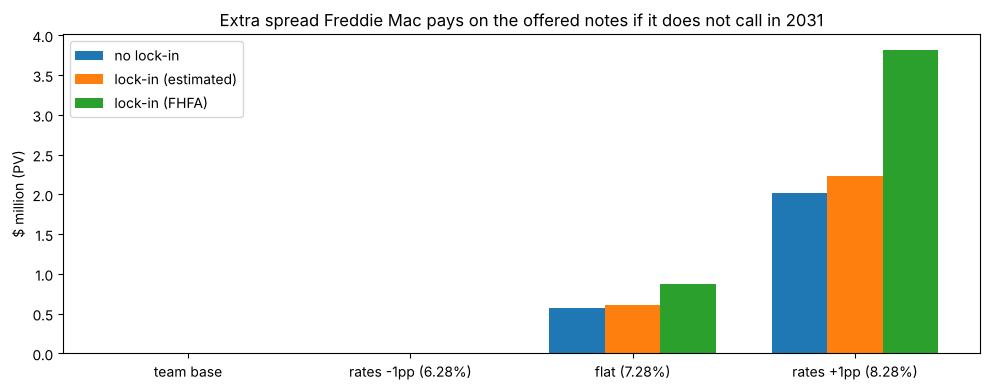

In [5]:
tot = grid.groupby(["path", "lockin_case"])[["net_cost_call_usd", "net_cost_no_call_usd", "extra_cost_no_call_usd", "call_value_usd"]].sum() / 1e6
tot = tot.unstack("lockin_case").loc[ORDER]
tot.to_csv(TABLES / "call_value_totals.csv")
display(tot.rename_axis("all offered notes, $mm"))

fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(ORDER)); w = 0.25
for j, c in enumerate(CASES):
    ax.bar(x + (j - 1) * w, tot[("extra_cost_no_call_usd", c)], w, label=c)
ax.set_xticks(x, ORDER); ax.set_ylabel("$ million (PV)")
ax.set_title("Extra spread Freddie Mac pays on the offered notes if it does not call in 2031")
ax.legend(); plt.tight_layout(); fig.savefig(FIGURES / "11_1_extra_cost_no_call.png", dpi=150); plt.show()

**Result.** **Total PV cost of risk transfer on the four offered notes ($437mm):**

| path | with call | without call | extra cost of not calling |
|---|---|---|---|
| team base | $6.8mm | $6.8mm | $0 |
| 6.28% | $5.2mm | $5.2mm | $0 |
| flat 7.28% | $9.3-9.6mm | $9.9-10.5mm | $0.57 / 0.61 / 0.87mm |
| +1 pp (8.28%) | $10.4-11.1mm | $12.4-14.9mm | **$2.02 / 2.23 / 3.82mm** |

The last column is for no / estimated / FHFA lock-in.

**What this means.**
- Moving from the base path to a high-rate world raises the cost of risk transfer by about 50% even with the call ($6.8mm to $10.4mm), because the notes live longer.
- Without the call it roughly doubles ($6.8mm to $12.4-14.9mm).
- Lock-in at FHFA's strength almost doubles the extra no-call cost ($2.0mm to $3.8mm). At our estimated strength it adds about 10%.
- Because the notes provide no protection in our scenarios, Freddie Mac has a clear reason to call when rates are high. So the "no call" case is unlikely, unless calling is costly for other reasons such as capital rules or the cost of new risk transfer.

## 6 · From duration to cost: a simple rule

**What this cell does.** It checks the net cost against a one-line formula that uses notebook 10's spread duration:

cost of risk transfer ≈ coupon spread × balance × spread duration

It shows the ratio of the two across all 48 note × path × lock-in × call cases, plots one against the other, and applies the rule to the extra cost of not calling for M-2B at +1 pp.

**Why it matters.** If the rule holds, the duration results in notebook 10 translate directly into the dollar cost of risk transfer. Every extra year of spread duration costs Freddie Mac about one year of coupon spread on the outstanding balance. That links Prof. Wallace's two questions, the duration of CRT notes and the cost of risk transfer, with one number.

net cost / (spread x balance x spread duration): min 1.026, max 1.064


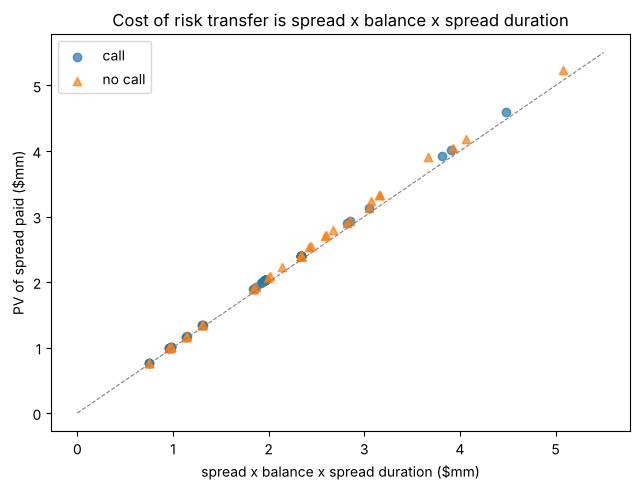

,"spread duration, call","spread duration, no call",extra cost ($mm),spread x balance x extra duration ($mm)
"M-2B, rates +1pp",,,,
no lock-in,3.98,6.24,1.21,1.11
lock-in (estimated),3.98,6.41,1.30,1.19
lock-in (FHFA),3.98,7.46,1.88,1.71


In [6]:
# spread durations from notebook 10 (same paths, lock-in cases and call assumptions)
dur = pd.read_csv(TABLES / "duration_grid.csv")
dur = dur.assign(call=dur["call"].map({"call 2031": "call", "no call": "no_call"}))
sd = dur.pivot_table(index=["path", "tranche", "lockin_case"], columns="call", values="spread_duration").add_prefix("spread_duration_").reset_index()
b = grid.merge(sd, on=["path", "tranche", "lockin_case"])
for c in ("call", "no_call"):
    b[f"rule_{c}_usd"] = b.face * b.coupon_spread_bps / 1e4 * b[f"spread_duration_{c}"]
    b[f"ratio_{c}"] = b[f"net_cost_{c}_usd"] / b[f"rule_{c}_usd"]
b.to_csv(TABLES / "call_value_duration_bridge.csv", index=False)
print(f"net cost / (spread x balance x spread duration): min {b[['ratio_call','ratio_no_call']].min().min():.3f}, "
      f"max {b[['ratio_call','ratio_no_call']].max().max():.3f}")

fig, ax = plt.subplots(figsize=(6.5, 5))
for c, mk in (("call", "o"), ("no_call", "^")):
    ax.scatter(b[f"rule_{c}_usd"] / 1e6, b[f"net_cost_{c}_usd"] / 1e6, marker=mk, label=c.replace("_", " "), alpha=0.7)
lim = [0, b[["net_cost_no_call_usd", "rule_no_call_usd"]].max().max() / 1e6 * 1.05]
ax.plot(lim, lim, color="grey", lw=0.8, ls="--")
ax.set_xlabel("spread x balance x spread duration ($mm)"); ax.set_ylabel("PV of spread paid ($mm)")
ax.set_title("Cost of risk transfer is spread x balance x spread duration"); ax.legend()
plt.tight_layout(); fig.savefig(FIGURES / "11_2_cost_vs_spread_duration.png", dpi=150); plt.show()

m2b = b[(b.tranche == "M-2B") & (b.path == "rates +1pp (8.28%)")].set_index("lockin_case").loc[CASES]
display(pd.DataFrame({"spread duration, call": m2b.spread_duration_call, "spread duration, no call": m2b.spread_duration_no_call,
                      "extra cost ($mm)": m2b.extra_cost_no_call_usd / 1e6,
                      "spread x balance x extra duration ($mm)": m2b.face * 0.013 * (m2b.spread_duration_no_call - m2b.spread_duration_call) / 1e6})
        .rename_axis("M-2B, rates +1pp"))

**Result.** **The rule works.** In all 96 call and no-call cases, the PV of the spread paid is between **1.03 and 1.06 times** coupon spread × balance × spread duration. The small gap comes from discounting at SOFR instead of SOFR + DM, and from the 360/365 day-count difference. For M-2B at +1 pp, the extra spread duration from not calling (3.98 → 6.24 / 6.41 / 7.46) predicts an extra cost of $1.11 / 1.19 / 1.71mm, against the exact $1.21 / 1.30 / 1.88mm.

**What this means.** The duration of a CRT note *is* its cost of risk transfer, scaled by spread and balance. Each extra year of spread duration on M-2B costs Freddie Mac about $0.5mm (1.3% × $37.9mm). So anything that lengthens the notes raises the cost of risk transfer in proportion: high rates, lock-in, or not calling.

## Conclusion: a first look at the whole question

1. **Lock-in (notebook 09).** Freddie Mac data supports a weak lock-in for all prepayments (0.025 per pp), against FHFA's 0.20 for home sales.
2. **Duration (notebook 10).** The notes' life and spread duration depend mostly on the rate path and the 2031 call. Lock-in amplifies the no-call case. M-2B's spread duration goes from 2.65 (base) to about 4.0 (high rates, with call) to 6.2-7.5 (no call).
3. **Cost of risk transfer (this notebook).**
   - The cost is about **coupon spread × balance × spread duration**.
   - On the offered notes it is $6.8mm PV in the base case, $10.4mm with high rates, and $12.4-14.9mm with high rates and no call.
   - The call is worth up to 0.5-0.7 points to M-2B investors.
4. **No protection in our scenarios.** The offered notes absorb no losses in any of our scenarios, so their entire cost is a premium for tail credit risk.

**The story for the paper.** Lock-in and high rates lengthen CRT notes, and longer notes cost Freddie Mac more for the same credit protection. The optional call caps that cost, so the call is the key policy lever.

**Next steps.**
- (a) Market forward-rate paths and a Monte Carlo of rates, so the call is valued as an option rather than scenario by scenario.
- (b) A rule for when Freddie Mac calls.
- (c) Tail-loss scenarios, so the protection side is not zero.
- (d) Threshold lock-in on the Freddie data.